# Predict New York City Airbnb Prices — Linear Regression Project

**Course:** AIML Batch (Unlox) | **Dataset:** New York City Airbnb Open Data (AB_NYC_2019)

**Goal:** Build a Linear Regression model that predicts the nightly `price` of an Airbnb listing in NYC, then check how good (and how fair) its predictions are.

**How to run in Google Colab:** Run the cells from top to bottom (Runtime → Run all). When the upload cell appears, upload `AB_NYC_2019_csv.zip` (or the unzipped `AB_NYC_2019.csv`).

## ⚙️ Setup: Import libraries and upload the data

In [36]:
# Libraries we need
import pandas as pd                 # tables (DataFrames)
import numpy as np                  # maths
import matplotlib.pyplot as plt     # plotting
import seaborn as sns               # nicer plots

from sklearn.model_selection import train_test_split   # train/test split
from sklearn.linear_model import LinearRegression      # the model
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style("whitegrid")          # clean plot style

In [37]:
# Upload the dataset (this only works inside Google Colab; elsewhere it is skipped)
try:
    from google.colab import files
    uploaded = files.upload()       # choose AB_NYC_2019_csv.zip (or AB_NYC_2019.csv)
except ImportError:
    print("Not running in Colab - using the file already in this folder.")

Saving AB_NYC_2019.csv to AB_NYC_2019 (3).csv


---
# Step 1: Exploratory Data Analysis (EDA) & Data Auditing

### Task 1.1 — Load the data and inspect shape, columns and data types

In [38]:
# pandas can read a .zip that contains one CSV directly.
# If you uploaded the unzipped file, change the name to 'AB_NYC_2019.csv'
df = pd.read_csv("AB_NYC_2019.csv")

print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))

Shape (rows, columns): (48895, 16)

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [39]:
# Data types and non-null counts for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [40]:
# First 5 rows
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


### Task 1.2 — Numerical vs. Categorical columns

Here is a breakdown of our variables to help us understand the data structure:

* **Identifiers (Labels only):**
  * `id`, `host_id`: Numerical labels (not real quantities).

* **Categorical / Text Columns (Nominal):**
  * `name`, `host_name`: Free-text columns.
  * `neighbourhood_group`: 5 unique boroughs with no inherent order.
  * `neighbourhood`: Over 200 distinct areas with no inherent order.
  * `room_type`: Types of accommodation (Entire home, Private room, Shared room).

* **Date Columns:**
  * `last_review`: Stored as a date string.

* **Continuous Numerical Columns:**
  * `latitude`, `longitude`: Geographic coordinates.
  * `price`: Nightly cost in USD (our target variable).
  * `reviews_per_month`: Average monthly feedback activity.

* **Discrete Numerical Columns (Counts / Whole Numbers):**
  * `minimum_nights`: Minimum stay required.
  * `number_of_reviews`: Total reviews received.
  * `calculated_host_listings_count`: Number of properties owned by the host.
  * `availability_365`: Number of available days in a year (0–365).

In [41]:
# Let pandas confirm our table above
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns :", numeric_cols)
print()
print("Categorical / text columns:", categorical_cols)

Numerical columns : ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical / text columns: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [42]:
# How many unique values does each categorical column have?
for col in ["neighbourhood_group", "neighbourhood", "room_type"]:
    print(f"{col}: {df[col].nunique()} unique values")

neighbourhood_group: 5 unique values
neighbourhood: 221 unique values
room_type: 3 unique values


### Task 1.3 — Check for missing values

In [43]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_table = pd.DataFrame({"Missing Count": missing_count, "Missing %": missing_percent})
missing_table = missing_table[missing_table["Missing Count"] > 0]   # keep only columns with missing data
missing_table

,Missing Count,Missing %
name,16,0.03
host_name,21,0.04
last_review,10052,20.56
reviews_per_month,10052,20.56


**What we found:**
- `last_review` → 10,052 missing (**20.56%**)
- `reviews_per_month` → 10,052 missing (**20.56%**)
- `name` → 16 missing (**0.03%**)
- `host_name` → 21 missing (**0.04%**)

All other columns are complete.

---
# Step 2: Data Cleaning & Handling Missing Values

### Task 2.1 — The `last_review` column
`last_review` is a date stored as text and ~20% of it is missing. A Linear Regression model cannot use text dates directly, so we must either drop it or engineer it.

In [44]:
# Are the missing last_review rows the listings that have NO reviews?
no_last_review = df[df["last_review"].isnull()]
print("Rows with missing last_review:", len(no_last_review))
print("Unique values of number_of_reviews in those rows:", no_last_review["number_of_reviews"].unique())

Rows with missing last_review: 10052
Unique values of number_of_reviews in those rows: [0]


**Decision: DROP `last_review`.**
The missing dates all belong to listings with **0 reviews** (a listing can't have a "last review date" if it was never reviewed). The useful information is already captured by `number_of_reviews`, and turning dates into numbers would add complexity (and still leave 10,000+ blanks) for very little gain. So we drop it.

In [45]:
df = df.drop(columns=["last_review"])
print("Columns now:", df.shape[1])

Columns now: 15


### Task 2.2 — The `reviews_per_month` column

In [46]:
# Investigate WHY reviews_per_month is missing
missing_rpm = df[df["reviews_per_month"].isnull()]
print("Missing rows:", len(missing_rpm))
print("number_of_reviews in those rows:", missing_rpm["number_of_reviews"].unique())

Missing rows: 10052
number_of_reviews in those rows: [0]


**Finding:** every row with a missing `reviews_per_month` has `number_of_reviews = 0`. No reviews means **0 reviews per month**, so the logical replacement value is **0** (not the mean or median, which would wrongly say these listings get reviews).

In [47]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
print("Missing values left in reviews_per_month:", df["reviews_per_month"].isnull().sum())

Missing values left in reviews_per_month: 0


### Task 2.3 — Drop irrelevant identifier columns

In [48]:
# id and host_id are just unique labels. name and host_name are text (and have a few missing values).
# They do not help a mathematical model, so we remove them.
df = df.drop(columns=["id", "name", "host_id", "host_name"])

print("Remaining columns:", list(df.columns))
print("Total missing values left:", df.isnull().sum().sum())

Remaining columns: ['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Total missing values left: 0


---
# Step 3: Outlier Identification & Treatment

### Task 3.1 — Visualise outliers in `price` and `minimum_nights`

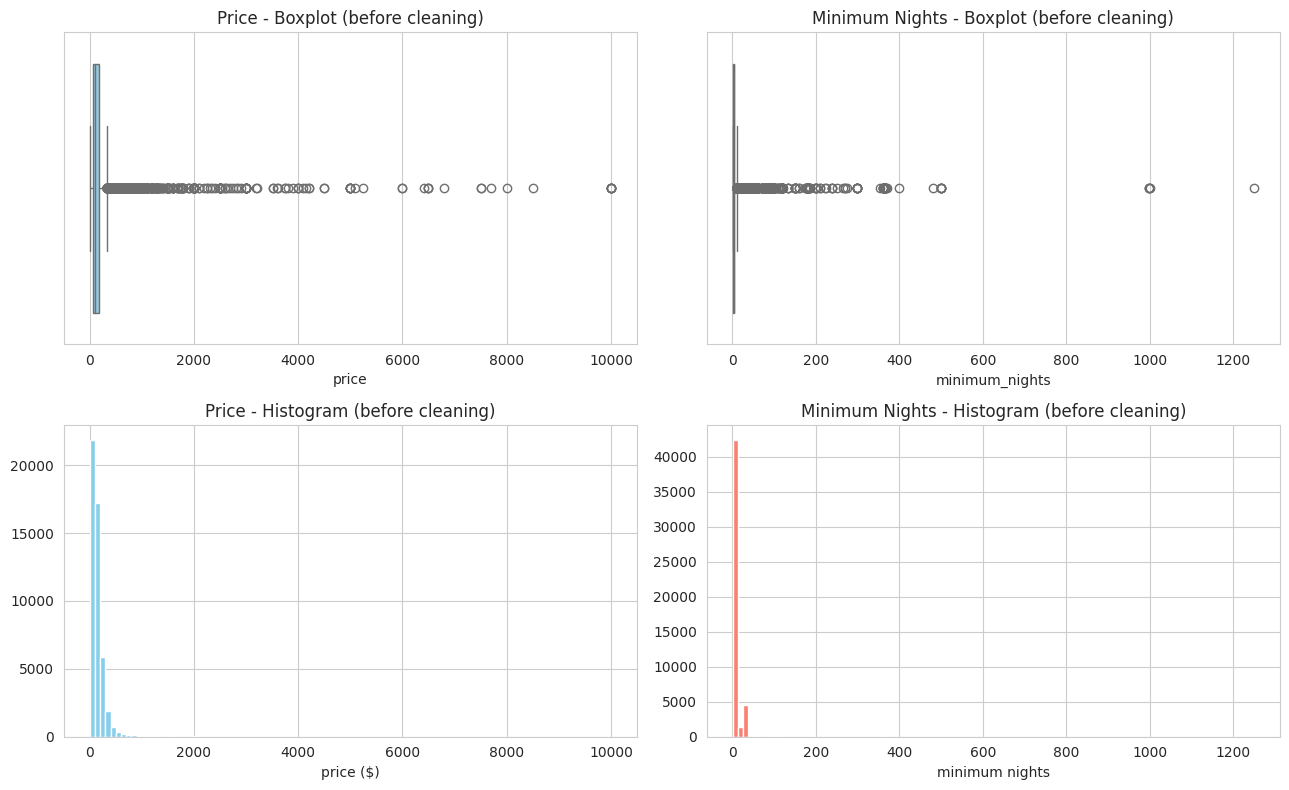

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Boxplots
sns.boxplot(x=df["price"], ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("Price - Boxplot (before cleaning)")
sns.boxplot(x=df["minimum_nights"], ax=axes[0, 1], color="salmon")
axes[0, 1].set_title("Minimum Nights - Boxplot (before cleaning)")

# Histograms
axes[1, 0].hist(df["price"], bins=100, color="skyblue")
axes[1, 0].set_title("Price - Histogram (before cleaning)")
axes[1, 0].set_xlabel("price ($)")
axes[1, 1].hist(df["minimum_nights"], bins=100, color="salmon")
axes[1, 1].set_title("Minimum Nights - Histogram (before cleaning)")
axes[1, 1].set_xlabel("minimum nights")

plt.tight_layout()
plt.show()

In [50]:
# Numbers behind the pictures
print(df[["price", "minimum_nights"]].describe().round(1))
print()
print("Most expensive listing: $", df["price"].max())
print("Longest minimum stay  :", df["minimum_nights"].max(), "nights")
print("Listings with price = $0:", (df["price"] == 0).sum())

         price  minimum_nights
count  48895.0         48895.0
mean     152.7             7.0
std      240.2            20.5
min        0.0             1.0
25%       69.0             1.0
50%      106.0             3.0
75%      175.0             5.0
max    10000.0          1250.0

Most expensive listing: $ 10000
Longest minimum stay  : 1250 nights
Listings with price = $0: 11


**What we see:** both columns are extremely **right-skewed**: most listings sit on the left, but a few extreme values (a $10,000/night listing, a 1,250-night minimum stay) stretch the axis. A Linear Regression line would get "pulled" towards these points. We also spotted **11 listings with a price of $0**, which are clearly data errors.

### Task 3.2 — Trim outliers using the 95th percentile rule

In [51]:
# Find the 95th percentile cut-off for each column
price_cap = df["price"].quantile(0.95)
nights_cap = df["minimum_nights"].quantile(0.95)
print(f"95th percentile of price          : ${price_cap:.0f}")
print(f"95th percentile of minimum_nights : {nights_cap:.0f} nights")

rows_before = len(df)

# Trimming: keep only rows at or below the cut-offs (and remove the $0 prices)
df = df[(df["price"] > 0) & (df["price"] <= price_cap) & (df["minimum_nights"] <= nights_cap)]

print(f"\nRows before: {rows_before} | Rows after: {len(df)} | Removed: {rows_before - len(df)} ({(rows_before - len(df)) / rows_before * 100:.1f}%)")

95th percentile of price          : $355
95th percentile of minimum_nights : 30 nights

Rows before: 48895 | Rows after: 45748 | Removed: 3147 (6.4%)


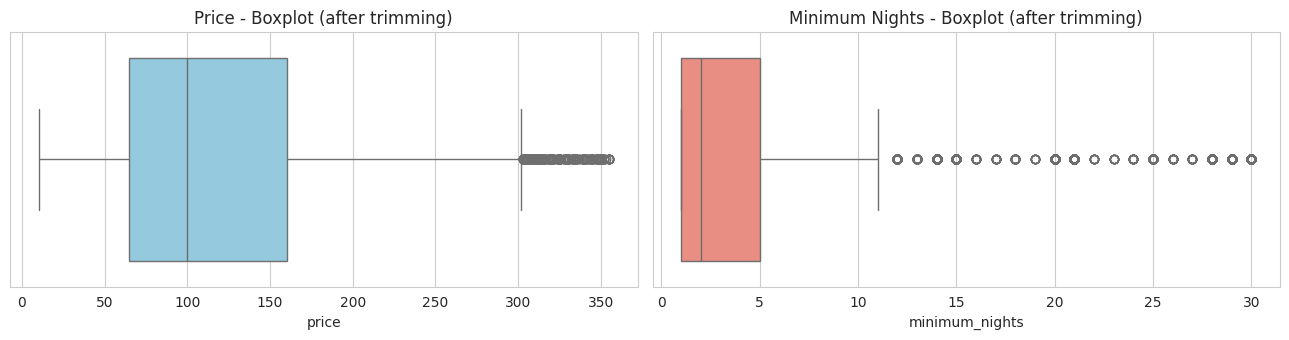

Max price now: 355 | Max minimum nights now: 30


In [52]:
# Check the result with new boxplots
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
sns.boxplot(x=df["price"], ax=axes[0], color="skyblue")
axes[0].set_title("Price - Boxplot (after trimming)")
sns.boxplot(x=df["minimum_nights"], ax=axes[1], color="salmon")
axes[1].set_title("Minimum Nights - Boxplot (after trimming)")
plt.tight_layout()
plt.show()

print("Max price now:", df["price"].max(), "| Max minimum nights now:", df["minimum_nights"].max())

✅ The luxury listings ($10,000/night) and long-term rentals (365+ nights) are gone, so the model now focuses on the **typical consumer market**.

---
# Step 4: Feature Selection & Categorical Encoding

### Task 4.1 — Address high cardinality

In [53]:
print("Unique neighbourhoods      :", df["neighbourhood"].nunique())
print("Unique neighbourhood_groups:", df["neighbourhood_group"].nunique())

Unique neighbourhoods      : 219
Unique neighbourhood_groups: 5


**Why keep only `neighbourhood_group` and drop `neighbourhood`? (The Curse of Dimensionality)**

One-hot encoding turns every unique value into its own column. `neighbourhood` has **200+ values**, so it would add **200+ new columns** (mostly zeros) to a dataset that only has ~7 real features. That causes problems:

1. **Too many features, too little data per feature** – many neighbourhoods have only a handful of listings, so the model learns noise instead of real patterns (overfitting).
2. **Slower and more complex** – the model has 200+ extra coefficients to estimate, and it becomes hard to explain.
3. **Multicollinearity** – many of these columns overlap with `neighbourhood_group` and with `latitude`/`longitude`, which already describe location.

`neighbourhood_group` has just **5 values**, so it keeps the useful location information while keeping the model simple. We drop `neighbourhood`.

In [54]:
df = df.drop(columns=["neighbourhood"])
print("Columns now:", list(df.columns))

Columns now: ['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


### Task 4.2 — One-Hot Encoding (with `drop_first=True` to avoid the Dummy Variable Trap)

In [55]:
# One-hot encode the two remaining text columns.
# drop_first=True removes one dummy column from each group so the columns are not perfectly
# predictable from each other (the "Dummy Variable Trap").
df_encoded = pd.get_dummies(df, columns=["neighbourhood_group", "room_type"], drop_first=True, dtype=int)

print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Shape after encoding: (45748, 14)


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


**Reading the dummy columns:** the dropped (reference) categories are **Bronx** (borough) and **Entire home/apt** (room type). For example, `room_type_Private room = 1` means the listing is a private room; if every room-type column is 0, it is an entire home/apartment.

---
# Step 5: Feature-Target Separation & Validation Split

### Task 5.1 — Separate features (X) and target (y)

In [56]:
X = df_encoded.drop(columns=["price"])   # everything except price = features
y = df_encoded["price"]                  # price = what we want to predict

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures used:", list(X.columns))

X shape: (45748, 13)
y shape: (45748,)

Features used: ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


### Task 5.2 — Train/Test split (80% / 20%) with a reproducibility seed

In [57]:
# random_state=42 makes the split identical every time, so results can be verified
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 36598
Testing rows : 9150


---
# Step 6: Model Training & Evaluation

### Task 6.1 — Fit a Linear Regression model

In [58]:
model = LinearRegression()        # create the model
model.fit(X_train, y_train)       # train it on the training data

print("Model trained!")
print("Intercept:", round(model.intercept_, 2))

Model trained!
Intercept: -18740.6


In [59]:
# Which features push the price up or down? (coefficients, in dollars)
coef_table = pd.DataFrame({"Feature": X.columns, "Coefficient ($)": model.coef_.round(2)})
coef_table.sort_values("Coefficient ($)", ascending=False).reset_index(drop=True)

,Feature,Coefficient ($)
0,neighbourhood_group_Manhattan,23.45
1,neighbourhood_group_Queens,5.67
2,calculated_host_listings_count,0.14
3,availability_365,0.07
4,number_of_reviews,-0.07
5,minimum_nights,-1.04
6,reviews_per_month,-1.06
7,neighbourhood_group_Brooklyn,-8.21
8,latitude,-76.23
9,room_type_Private room,-79.12


### Task 6.2 — Predict prices on the hidden test data

In [60]:
y_pred = model.predict(X_test)

# Quick look at 5 predictions vs. the real prices
pd.DataFrame({"Actual": y_test.values[:5], "Predicted": y_pred[:5].round(2)})

,Actual,Predicted
0,80,107.11
1,73,145.83
2,186,184.77
3,150,166.01
4,229,140.96


### Task 6.3 — Evaluation metrics

In [61]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-squared (R2): {r2:.4f}  -> the model explains {r2 * 100:.1f}% of the variation in price")
print(f"MAE           : ${mae:.2f}  -> on average, predictions are off by this many dollars")
print(f"MSE           : {mse:.2f}")
print(f"RMSE          : ${rmse:.2f}  -> like MAE but punishes big mistakes more")

# For context: how well would a 'dumb' model do that always guesses the average training price?
baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"\nFor comparison, always guessing the average price gives an MAE of ${baseline_mae:.2f}")

R-squared (R2): 0.4868  -> the model explains 48.7% of the variation in price
MAE           : $38.32  -> on average, predictions are off by this many dollars
MSE           : 2760.62
RMSE          : $52.54  -> like MAE but punishes big mistakes more

For comparison, always guessing the average price gives an MAE of $58.52


**How to read these:**
- **R²** tells us what share of the ups and downs in price the model understands (1.0 = perfect, 0 = no better than guessing the average).
- **MAE** is the average size of the mistake in real dollars.
- **MSE / RMSE** square the errors first, so a few very wrong predictions make them much larger. RMSE being bigger than MAE means some predictions are far off.

---
# Step 7: Residual Analysis & Interpretation

### Task 7.1 — Actual vs. Predicted prices

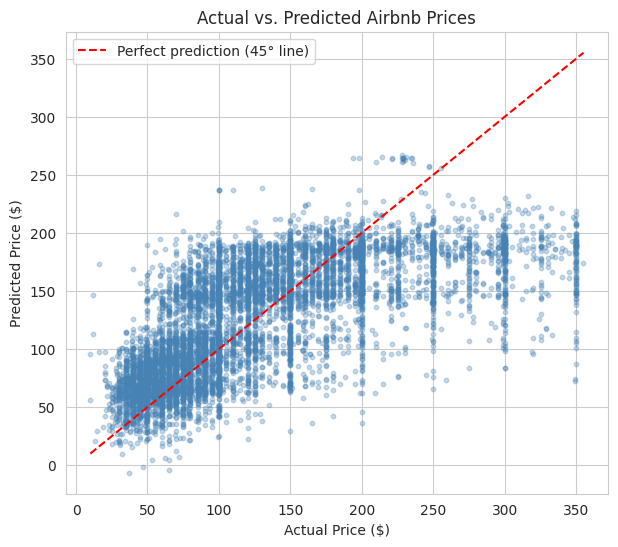

In [62]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=10, color="steelblue")

# 45-degree line = a "perfect" prediction (predicted = actual)
low, high = y_test.min(), y_test.max()
plt.plot([low, high], [low, high], color="red", linestyle="--", label="Perfect prediction (45° line)")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted Airbnb Prices")
plt.legend()
plt.show()

### Task 7.2 — Residual plot and error distribution

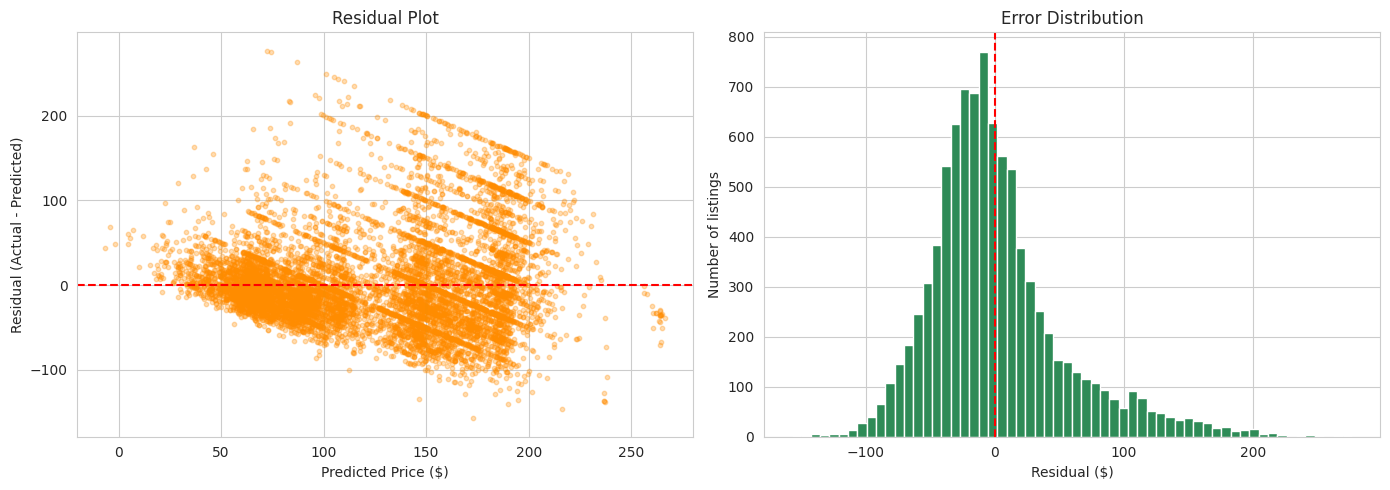

In [63]:
residuals = y_test - y_pred      # error = actual - predicted

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs predicted values
axes[0].scatter(y_pred, residuals, alpha=0.3, s=10, color="darkorange")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Price ($)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residual Plot")

# Histogram of errors
axes[1].hist(residuals, bins=60, color="seagreen")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual ($)")
axes[1].set_ylabel("Number of listings")
axes[1].set_title("Error Distribution")

plt.tight_layout()
plt.show()

### Task 7.3 — Does the model do better on cheap or expensive listings?

In [64]:
# Put the test results in one table
results = pd.DataFrame({"actual": y_test.values, "predicted": y_pred})
results["error"] = results["actual"] - results["predicted"]        # + = we under-predicted
results["abs_error"] = results["error"].abs()
results["pct_error"] = results["abs_error"] / results["actual"] * 100

# Split the listings into 4 equal-sized price groups (cheapest 25% ... most expensive 25%)
results["price_group"] = pd.qcut(results["actual"], q=4,
                                 labels=["1: Cheapest 25%", "2: Lower-mid", "3: Upper-mid", "4: Most expensive 25%"])

summary = results.groupby("price_group", observed=True).agg(
    avg_actual_price=("actual", "mean"),
    MAE=("abs_error", "mean"),
    avg_pct_error=("pct_error", "mean"),
    avg_error=("error", "mean")            # average bias: + means model guessed too LOW
).round(2)
summary

,avg_actual_price,MAE,avg_pct_error,avg_error
price_group,,,,
1: Cheapest 25%,50.06,26.21,57.93,-23.44
2: Lower-mid,85.16,31.69,37.23,-19.74
3: Upper-mid,132.73,31.32,24.38,-12.67
4: Most expensive 25%,229.90,64.11,25.33,60.34


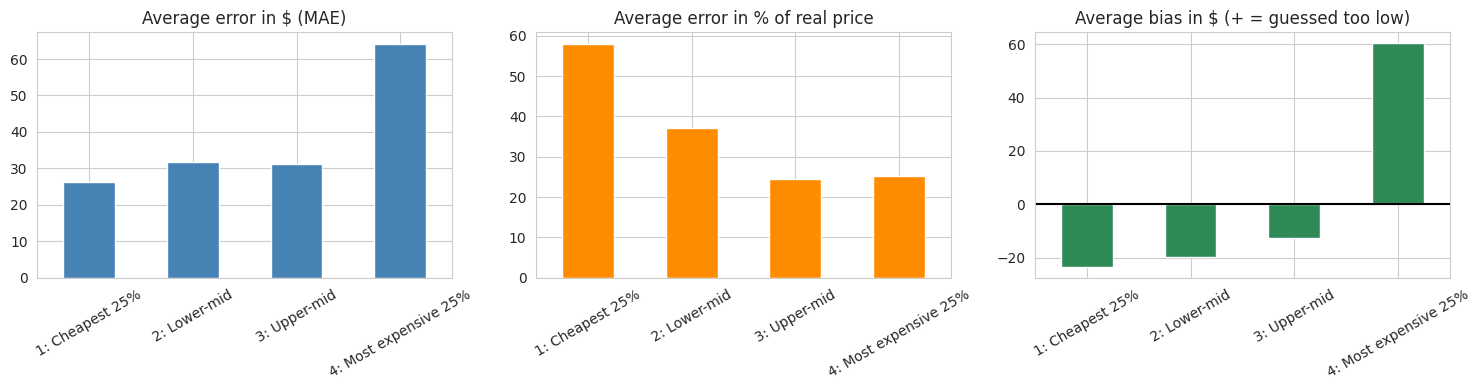

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

summary["MAE"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Average error in $ (MAE)")
axes[0].set_xlabel("")

summary["avg_pct_error"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Average error in % of real price")
axes[1].set_xlabel("")

summary["avg_error"].plot(kind="bar", ax=axes[2], color="seagreen")
axes[2].axhline(0, color="black")
axes[2].set_title("Average bias in $ (+ = guessed too low)")
axes[2].set_xlabel("")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Answer to the final project question

**Does the model perform better on cheap or expensive listings, and why?**

* **On cheap listings ($50–$85 range):** The model has a smaller error in absolute terms (off by ~$26 to $32), but a **high percentage error (up to 58%)** because even a small dollar miss is a large portion of a cheap listing's actual price. It also heavily **overestimates** their value.
* **On expensive listings (top 25%, averaging ~$230):** The model has a much larger error in absolute terms (off by ~$64 on average), but a **lower percentage error (around 25%)**. It heavily **underestimates** these listings.

**Why?**
1. **Regression Line Pull:** Linear regression fits a straight line that pulls predictions toward the global average, resulting in systemic over-prediction at the low end and under-prediction at the high end.
2. **Missing Information:** Important predictors of premium pricing (such as views, luxury finishes, square footage, or specific amenities) are completely missing from our dataset.